# Portfolio-opdracht 1: Voorspel herseninfarct 

**Groep 3**

| Naam | Studentnummer | Kaggle-gebruikersnaam |
|---|---|---|
| Melih Bagci | 24099112 | Melih Bagci |
| Gamal Al Sabaeei | 25023497 | Gamal AL-sabaei |
| Rayan el Mourabit | 25025678 | Rayanell |

## 1. Inleiding

MedPredict is een medisch technologiebedrijf dat ziekenhuizen en zorginstellingen helpt om gezondheidsrisico's vroeg te herkennen. Het bedrijf beschikt over geanonimiseerde patiëntgegevens: demografische kenmerken, leefstijlfactoren en medische informatie.

Een herseninfarct is een groot gezondheidsprobleem: in 2021 was het wereldwijd de derde doodsoorzaak, goed voor ongeveer 10% van alle sterfgevallen (WHO, 2024). Als patiënten met een verhoogd risico eerder worden herkend, kunnen artsen hen gerichter opvolgen en preventieve zorg bieden.

MedPredict wil daarom weten of de patiëntgegevens gebruikt kunnen worden om deze risicopatiënten automatisch te herkennen. Om verschillende oplossingen te vergelijken, organiseert MedPredict een interne Kaggle-competitie tussen de teams van de opleiding Applied Data Science & AI.

Ons team (Groep 3) is als junior data scientists ingezet om dit model te ontwikkelen. Naast een goede score op Kaggle kijken we kritisch naar de data, onze keuzes en de betrouwbaarheid van het model, omdat verkeerde voorspellingen in deze medische toepassing gevolgen kunnen hebben voor patiënten.

## 2. Probleemstelling

MedPredict zoekt een model dat:
- patiënten met een herseninfarct zo goed mogelijk herkent (zo min mogelijk gemiste patiënten)
- niet te veel vals alarm geeft, omdat dat artsen tijd kost en patiënten onnodig ongerust maakt
- uitlegbaar is, zodat artsen de voorspelling kunnen vertrouwen en controleren

**Hoofdvraag:** in hoeverre kan een machine learning model op basis van persoonskenmerken, medische en leefstijlkenmerken herkennen welke patiënten een verhoogd risico op een herseninfarct hebben?

**Deelvragen:**
1. Hoe ziet de data eruit en is deze geschikt voor machine learning? 
2. Met welke metrics beoordelen we hoe goed een model is? 
3. Welk model presteert het best, en met welke hyperparameters? 
4. Welk model adviseren we aan artsen, en waarom? 

## 3. De dataset

### 3.1 Bestanden
De data komt uit de Kaggle-competitie Predicting stroke 2026-27. Elke rij is één geanonimiseerde patiënt.

| Bestand | Inhoud | 
|---|---|
| train.csv | 33.550 patiënten
| test.csv | 8.388 patiënten
| sample_submission.csv | Kolommen id en stroke 

### 3.2 Data inladen
We laden de train- en testset en bekijken de eerste vijf rijen.

In [7]:
"""Exploratieve data-analyse voor de Kaggle-competitie Predicting stroke."""
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")

print(train_df.shape, test_df.shape)

(33550, 22) (8388, 21)


In [2]:
train_df.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


**Observaties:**
- De trainset heeft 33.550 rijen en 22 kolommen, de testset heeft 8.388 rijen en 21 kolommen. De ontbrekende kolom in de test is de target stroke, die wij moeten voorspellen.
- Elke rij is één patiënt met een uniek id.

### 3.3 Beschrijving van de kolommen

De dataset bevat 22 kolommen.

| Kolom | Beschrijving | Meetniveau |
|---|---|---|
| id| Uniek nummer per patiënt | Nominaal |
| age | Leeftijd in jaren (baby's hebben decimalen, bijv. 0,08) | Ratio |
| hypertension | Hoge bloeddruk (1 = ja) | Nominaal |
| heart_disease | Hartziekte (1 = ja) | Nominaal  |
| avg_glucose_level | Gemiddelde bloedsuikerspiegel (mg/dL) | Ratio |
| bmi | Body Mass Index: gewicht (kg) / lengte² (m²) | Ratio |
| gender_Female / _Male / _Other | Geslacht | Nominaal |
| ever_married_No / _Yes | Ooit getrouwd geweest | Nominaal |
| work_type_Govt_job | Werkt bij de overheid | Nominaal |
| work_type_Never_worked | Heeft nooit gewerkt | Nominaal |
| work_type_Private | Werkt in de private sector | Nominaal |
| work_type_Self-employed | Zelfstandig ondernemer | Nominaal |
| work_type_children | Kind (werkt nog niet) | Nominaal |
| Residence_type_Rural / _Urban | Woont op het platteland / in de stad | Nominaal |
| smoking_status_formerly smoked | Heeft vroeger gerookt | Nominaal |
| smoking_status_never smoked | Heeft nooit gerookt | Nominaal |
| smoking_status_smokes | Rookt momenteel | Nominaal |
| stroke| Target: herseninfarct gehad (1 = ja, 0 = nee) | Nominaal  |

## 4. Exploratieve Data Analyse

In de EDA leren we de data kennen voordat we gaan modelleren. We onderzoeken hoe de data eruitziet, of deze bruikbaar is voor machine learning en welke kenmerken samenhangen met een herseninfarct. De bevindingen gebruiken we om keuzes te onderbouwen bij het opschonen van de data en bij het modelleren.


### 4.1 Datatypes en basisstatistieken

In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          

Voor de numerieke features (`age`, `avg_glucose_level` en `bmi`) tonen we de basisstatistieken: gemiddelde, standaardafwijking, minimum, kwartielen en maximum. Deze statistieken zijn alleen zinvol voor variabelen op ratio- of intervalniveau. Hiermee krijgen we inzicht in de spreiding van de data en kunnen we mogelijke uitschieters opsporen.

In [9]:
NUMERIC_COLS = ["age", "avg_glucose_level", "bmi"]

train_df[NUMERIC_COLS].describe().round(2)

,age,avg_glucose_level,bmi
count,33550.00,33550.00,33550.00
mean,41.82,103.59,28.60
std,22.48,42.13,7.78
min,0.08,55.01,10.10
25%,24.00,77.46,23.30
50%,43.00,91.32,27.70
75%,59.00,111.44,32.80
max,82.00,281.59,97.60


Voor binaire variabelen zijn een gemiddelde en standaardafwijking weinig betekenisvol. Daarom tonen we per kolom het aantal en het percentage patiënten met de waarde 1. Zo zien we hoe vaak elke categorie voorkomt en hoe onevenwichtig de target `stroke` is.

In [ ]:
def binary_summary(df: pd.DataFrame, exclude: list[str]) -> pd.DataFrame:
    """Geef per binaire kolom het aantal en percentage enen (True / 1)."""
    binary_cols = [col for col in df.columns
                   if col not in exclude and df[col].nunique() == 2]
    summary = pd.DataFrame({
        # True telt als 1, dus de som is het aantal enen
        "aantal_1": df[binary_cols].sum().astype(int),
        # Het gemiddelde van 0/1 is het aandeel enen; x 100 geeft procenten
        "percentage_1": (df[binary_cols].mean() * 100).round(2),
    })
    return summary


binary_summary(train_df, exclude=["id"] + NUMERIC_COLS)

,aantal_1,percentage_1
hypertension,2957,8.81
heart_disease,1444,4.30
gender_Female,20032,59.71
gender_Male,13512,40.27
gender_Other,6,0.02
ever_married_No,12124,36.14
ever_married_Yes,21426,63.86
work_type_Govt_job,4156,12.39
work_type_Never_worked,141,0.42
work_type_Private,19279,57.46


**Observaties:**
- **De target stroke is sterk onevenwichtig:** slechts 517 patiënten (1,54%) hebben een herseninfarct gehad. Een model dat altijd "geen stroke" voorspelt, heeft al 98,5% goed.
- **Medische kenmerken:** 8,8% heeft hoge bloeddruk (hypertension) en 4,3% een hartziekte (heart_disease).
- **Zeer kleine groepen:** gender_Other komt maar 6 keer voor (0,02%) en work_type_Never_worked 141 keer (0,42%). Deze groepen zijn te klein om betrouwbaar iets van te leren.


In [ ]:
# Duplicaten: id weglaten, want dat is per patiënt altijd uniek
print("Duplicaten (zonder id):", train_df.drop(columns="id").duplicated().sum())
# Hoeveel patiënten met gender_Other zitten er in de testset?
print("gender_Other in test:", test_df["gender_Other"].sum())

Duplicaten (zonder id): 0
gender_Other in test: 1


### 4.2 Geschiktheid voor scikit-learn

Scikit-learn stelt de volgende minimale eisen aan de data:
1. **Alle features zijn numeriek.** Categorische variabelen moeten omgezet zijn (bijv. met one-hot encoding).
2. **Geen ontbrekende waarden (NaN).** De meeste modellen kunnen hier niet mee omgaan.
3. **Features en target zijn gescheiden** in een feature-matrix X en een targetvector Y.
4. **De train- en testset hebben dezelfde features** in dezelfde volgorde.

Hieronder controleren we deze eisen.

In [11]:
def check_sklearn_ready(train: pd.DataFrame, test: pd.DataFrame,
                        target: str) -> None:
    """Controleer of de data voldoet aan de minimale eisen van scikit-learn."""
    features = train.drop(columns=target)
    non_numeric = features.select_dtypes(exclude=["number", "bool"]).columns
    print("Niet-numerieke kolommen:", list(non_numeric))
    print("Ontbrekende waarden train:", train.isna().sum().sum())
    print("Ontbrekende waarden test:", test.isna().sum().sum())
    print("Zelfde features in train en test:",
          list(features.columns) == list(test.columns))


check_sklearn_ready(train_df, test_df, target="stroke")

Niet-numerieke kolommen: []
Ontbrekende waarden train: 0
Ontbrekende waarden test: 0
Zelfde features in train en test: True


De dummy-kolommen hebben het datatype bool (True/False). Scikit-learn accepteert dit wel, maar we zetten ze om naar integers (1/0). Zo hebben alle binaire kolommen hetzelfde datatype en werken ze betrouwbaar. We passen dezelfde omzetting toe op de testset, zodat beide sets hetzelfde formaat hebben.

In [10]:
def bool_to_int(df: pd.DataFrame) -> pd.DataFrame:
    """Zet alle boolean kolommen om naar integers (0/1)."""
    df = df.copy()
    bool_cols = df.select_dtypes(include="bool").columns
    df[bool_cols] = df[bool_cols].astype(int)
    return df


train_df = bool_to_int(train_df)
test_df = bool_to_int(test_df)
print(train_df.dtypes.value_counts())

int32      15
int64       4
float64     3
Name: count, dtype: int64


**Conclusie:** de data voldoet aan de minimale eisen van scikit-learn. Alle kolommen zijn numeriek, er zijn geen ontbrekende waarden en de train- en testset hebben dezelfde features. De boolean dummy-kolommen zijn omgezet naar integers (0/1). De kolom id is niet relevant voor het model en wordt bij het opschonen verwijderd.

### 4.3 Relaties tussen features en target

#### 4.3.1 Numerieke features

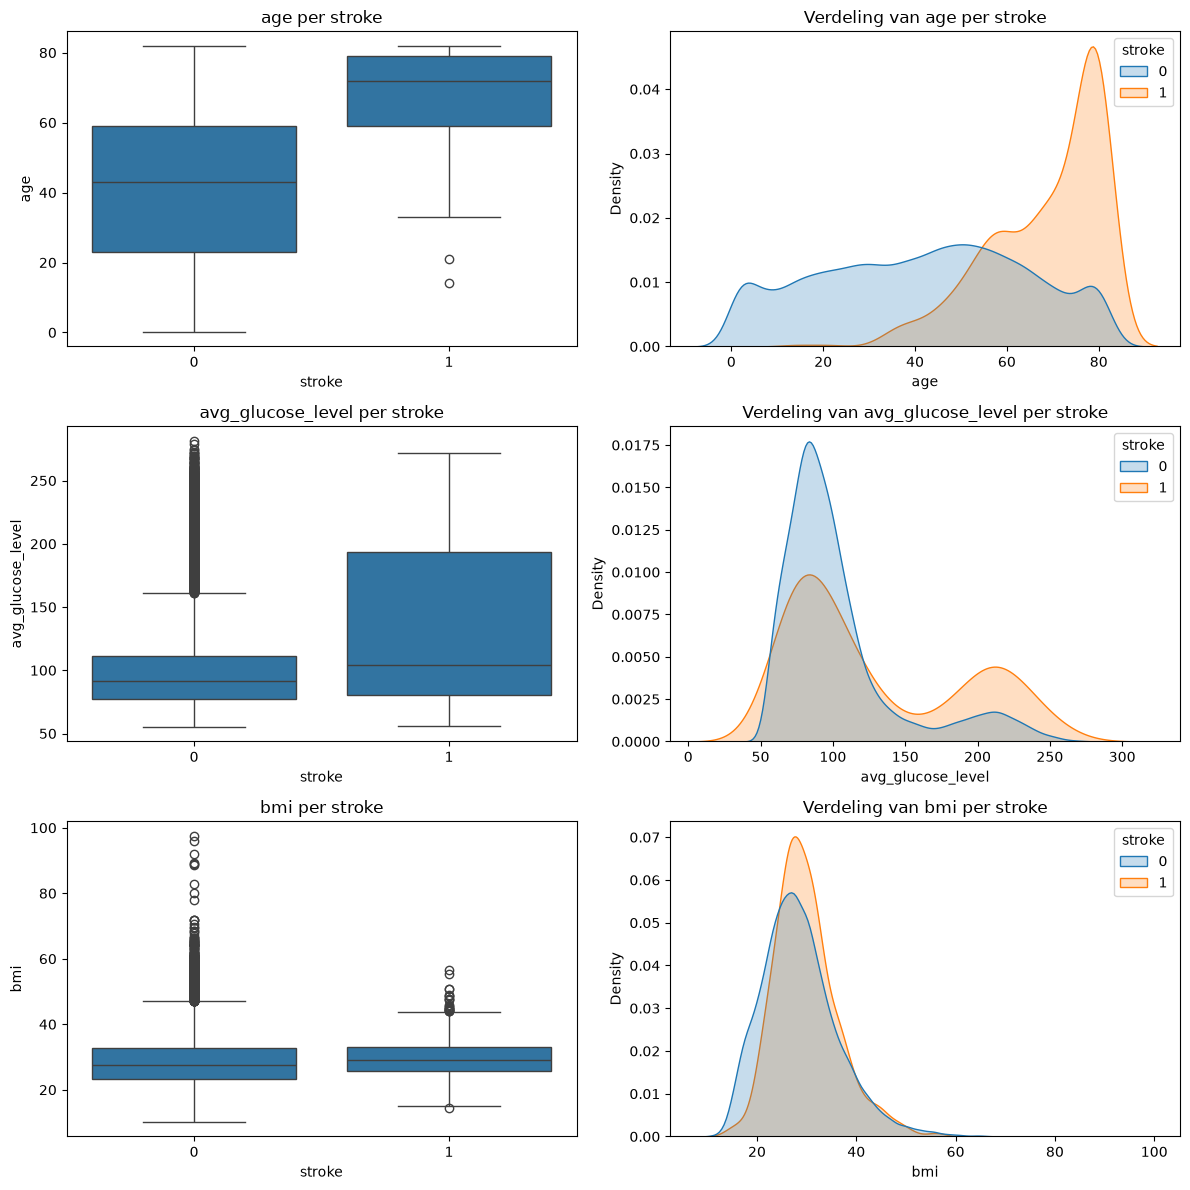

In [9]:
def plot_numeric_vs_target(df: pd.DataFrame, cols: list[str],
                           target: str) -> None:
    """Toon per numerieke feature een boxplot en een dichtheidsplot per klasse."""
    fig, axes = plt.subplots(len(cols), 2, figsize=(12, 4 * len(cols)))
    for i, col in enumerate(cols):
        sns.boxplot(data=df, x=target, y=col, ax=axes[i, 0])
        axes[i, 0].set_title(f"{col} per {target}")
        sns.kdeplot(data=df, x=col, hue=target, common_norm=False,
                    fill=True, ax=axes[i, 1])
        axes[i, 1].set_title(f"Verdeling van {col} per {target}")
    plt.tight_layout()
    plt.show()


plot_numeric_vs_target(train_df, NUMERIC_COLS, target="stroke")

**Observaties:**
- **`age`** heeft de duidelijkste relatie met `stroke`. De mediane leeftijd van patiënten met een herseninfarct ligt rond de 72 jaar, tegenover ongeveer 43 jaar bij patiënten zonder. Onder de 40 jaar komt een herseninfarct nauwelijks voor.
- **`avg_glucose_level`** heeft een bimodale verdeling: een piek rond 80–100 mg/dL en een tweede piek rond 200–250 mg/dL. Deze tweede piek is relatief veel groter bij patiënten met een herseninfarct, wat wijst op een verhoogd risico bij een hoge bloedsuikerspiegel.
- **`bmi`** laat slechts een klein verschil zien tussen beide groepen. De extreme uitschieters (bmi > 60) komen alleen voor bij patiënten zonder herseninfarct.

#### 1.4.2 Binaire features

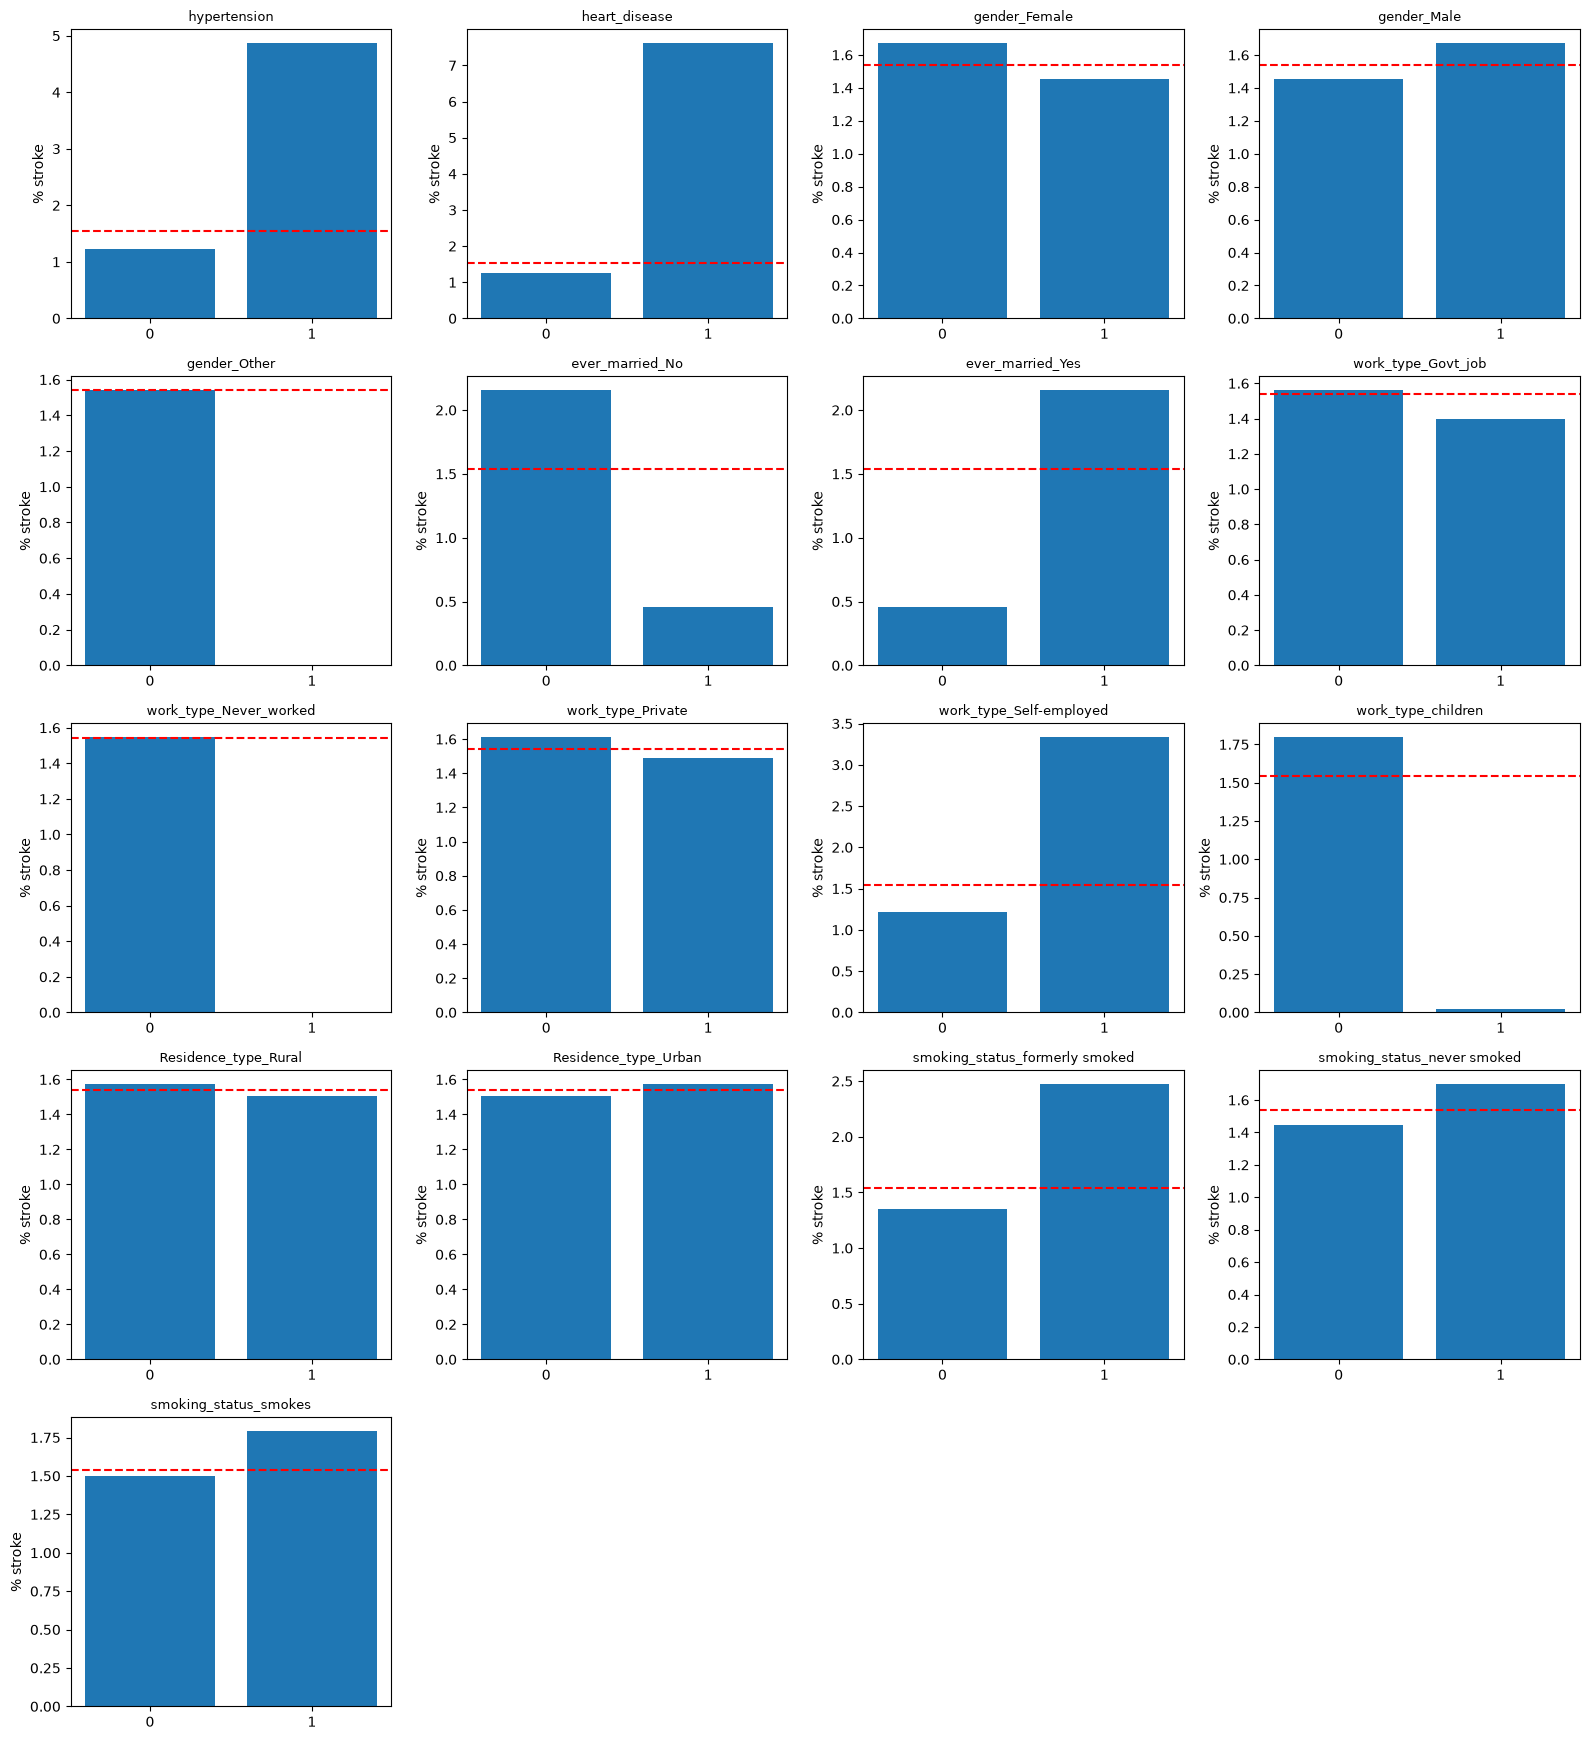

In [10]:
def plot_stroke_rate(df: pd.DataFrame, cols: list[str], target: str) -> None:
    """Toon per binaire feature het percentage stroke bij waarde 0 en 1."""
    n_cols = 4
    n_rows = -(-len(cols) // n_cols)  # afronden naar boven
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
    axes = axes.flatten()
    overall_rate = df[target].mean() * 100
    for i, col in enumerate(cols):
        rates = df.groupby(col)[target].mean() * 100
        axes[i].bar(rates.index.astype(str), rates.values)
        axes[i].axhline(overall_rate, color="red", linestyle="--")
        axes[i].set_title(col, fontsize=9)
        axes[i].set_ylabel("% stroke")
    for j in range(len(cols), len(axes)):
        axes[j].set_visible(False)
    plt.tight_layout()
    plt.show()


BINARY_COLS = [col for col in train_df.columns
               if col not in ["id", "stroke"] + NUMERIC_COLS]
plot_stroke_rate(train_df, BINARY_COLS, target="stroke")

**Observaties:**
- **`heart_disease`** en **`hypertension`** hebben de sterkste relatie met `stroke`: bij patiënten met een hartziekte is het percentage herseninfarcten ongeveer 6 keer zo hoog (7,6% vs. 1,25%), bij hoge bloeddruk ongeveer 4 keer zo hoog (4,9% vs. 1,2%).
- **`ever_married_Yes`**, **`work_type_Self-employed`** en **`smoking_status_formerly smoked`** laten een verhoogd percentage zien, terwijl **`work_type_children`** bijna geen herseninfarcten heeft. Dit wordt waarschijnlijk (deels) verklaard door **leeftijd**: getrouwde, zelfstandige en voormalige rokers zijn gemiddeld ouder. Leeftijd is hier een *confounder*.
- **`gender`**, **`Residence_type`**, **`work_type_Govt_job`**, **`work_type_Private`** en de overige rookcategorieën laten nauwelijks verschil zien.
- **`gender_Other`** en **`work_type_Never_worked`** bevatten geen enkele patiënt met een herseninfarct, omdat deze groepen erg klein zijn.

#### 1.4.3 Correlatie met de target

De target `stroke` is binair (nominaal). De keuze van de correlatiecoëfficiënt hangt af van het meetniveau van de feature:
- **Numerieke feature × binaire target:** de point-biserial correlatie. Dit is wiskundig gelijk aan Pearson's r wanneer één variabele 0/1 is. Omdat `avg_glucose_level` scheef verdeeld is, berekenen we ook **Spearman's rho**, die op rangordes werkt en minder gevoelig is voor uitschieters.
- **Binaire feature × binaire target:** **Cramér's V**. Bij een 2×2-tabel is deze gelijk aan de absolute waarde van de phi-coëfficiënt.

In [11]:
from scipy.stats import chi2_contingency, pointbiserialr, spearmanr


def cramers_v(x: pd.Series, y: pd.Series) -> float:
    """Bereken Cramér's V tussen twee categorische variabelen."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    k = min(table.shape) - 1
    return (chi2 / (n * k)) ** 0.5


def target_correlations(df: pd.DataFrame, numeric: list[str],
                        binary: list[str], target: str) -> pd.DataFrame:
    """Bereken per feature de passende correlatie met de target."""
    rows = []
    for col in numeric:
        rows.append({"feature": col, "methode": "point-biserial",
                     "waarde": pointbiserialr(df[col], df[target])[0]})
        rows.append({"feature": col, "methode": "Spearman",
                     "waarde": spearmanr(df[col], df[target])[0]})
    for col in binary:
        rows.append({"feature": col, "methode": "Cramér's V",
                     "waarde": cramers_v(df[col], df[target])})
    result = pd.DataFrame(rows).round(3)
    return result.sort_values("waarde", ascending=False, key=abs)


target_correlations(train_df, NUMERIC_COLS, BINARY_COLS, target="stroke")

,feature,methode,waarde
0,age,point-biserial,0.149
1,age,Spearman,0.148
7,heart_disease,Cramér's V,0.105
6,hypertension,Cramér's V,0.084
2,avg_glucose_level,point-biserial,0.077
11,ever_married_No,Cramér's V,0.066
12,ever_married_Yes,Cramér's V,0.066
16,work_type_Self-employed,Cramér's V,0.062
17,work_type_children,Cramér's V,0.051
3,avg_glucose_level,Spearman,0.044


**Observaties:**
- De volgorde bevestigt de visualisaties: `age` heeft de sterkste correlatie met `stroke`, gevolgd door `heart_disease`, `hypertension` en `avg_glucose_level`.
- Bij `avg_glucose_level` is de point-biserial correlatie (0,077) hoger dan Spearman's rho (0,044). Het effect zit vooral in de hoge waarden (de tweede piek rond 200–250 mg/dL). Pearson is gevoelig voor deze grote waarden, terwijl Spearman alleen naar de rangorde kijkt.
- `ever_married_No` en `ever_married_Yes` hebben exact dezelfde waarde, omdat ze elkaars tegenovergestelde zijn. Hetzelfde geldt voor `Residence_type_Rural` en `Residence_type_Urban`. Eén kolom per paar is dus overbodig.
- Alle correlaties zijn laag (< 0,15). Dit komt deels door de sterke onbalans van de target. Een lage correlatie betekent bovendien niet dat een feature onbruikbaar is: correlatiecoëfficiënten meten alleen een monotone of lineaire samenhang, terwijl modellen zoals decision trees ook niet-lineaire verbanden en interacties kunnen benutten.

### 1.5 Belangrijkste bevindingen

1. **Sterk onevenwichtige target:** slechts 1,54% van de patiënten heeft een herseninfarct gehad. Accuracy is daardoor geen geschikte metric, en technieken voor imbalanced data zijn nodig (zie hoofdstuk 3).
2. **Leeftijd is de belangrijkste voorspeller:** herseninfarcten komen vrijwel alleen voor bij patiënten ouder dan 40 jaar.
3. **Medische factoren:** `heart_disease`, `hypertension` en een hoge `avg_glucose_level` verhogen het risico duidelijk.
4. **Leeftijd als confounder:** de verbanden bij `ever_married`, `work_type` en `smoking_status` worden waarschijnlijk grotendeels verklaard door leeftijd.
5. **Zwakke features:** `gender`, `Residence_type` en `bmi` hebben nauwelijks een relatie met `stroke`.
6. **Datakwaliteit:** geen ontbrekende waarden en geen duplicaten, wel uitschieters in `bmi` (tot 97,6) en een zeer kleine groep `gender_Other` (6 patiënten).
7. **Redundante kolommen:** een aantal dummy-paren (bijv. `ever_married_No` / `_Yes`) bevat dezelfde informatie.

### 1.6 Data opschonen

Op basis van de EDA voeren we de volgende stappen uit:
1. **`id` verwijderen uit de features.** Dit is een willekeurig nummer zonder relatie met `stroke`. De id's van de testset bewaren we apart voor de Kaggle-submission.
2. **Patiënten met `gender_Other` verwijderen uit de trainset.** Deze groep bevat slechts 6 patiënten, te weinig om iets van te leren. Daarna bevat de kolom alleen nog nullen en wordt ze verwijderd. Uit de testset verwijderen we geen rijen, omdat Kaggle voor elke patiënt een voorspelling verwacht.
3. **Redundante dummy-kolommen verwijderen.** Per categorische variabele laten we één dummy weg, omdat deze volledig af te leiden is uit de andere kolommen. Dit voorkomt perfecte multicollineariteit (de *dummy variable trap*), wat vooral van belang is voor lineaire modellen zoals logistic regression.
4. **Uitschieters in `bmi` behouden.** Waarden boven de 60 zijn zeldzaam, maar medisch mogelijk en komen ook in de testset voor. Door ze te behouden leert het model ook met deze waarden om te gaan.
5. **Jonge kinderen behouden.** Een leeftijd van 0,08 jaar is realistisch (baby's) en deze groep komt ook in de testset voor.


In [12]:
DROP_COLS = [
    "id",
    "gender_Other",
    "gender_Female",
    "ever_married_No",
    "work_type_Never_worked",
    "Residence_type_Rural",
]


def clean_data(train: pd.DataFrame, test: pd.DataFrame
               ) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series]:
    """Verwijder irrelevante rijen en kolommen uit de train- en testset."""
    test_ids = test["id"].copy()
    train = train[train["gender_Other"] == 0].copy()
    train = train.drop(columns=DROP_COLS)
    test = test.drop(columns=DROP_COLS)
    return train, test, test_ids


train_clean, test_clean, test_ids = clean_data(train_df, test_df)
print("Train:", train_clean.shape)
print("Test:", test_clean.shape)
print("Kolommen:", list(train_clean.columns))

Train: (33544, 16)
Test: (8388, 15)
Kolommen: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'stroke']


De ene patiënt met `gender_Other` in de testset heeft na het verwijderen van de kolommen de waarde `gender_Male = 0` en wordt door het model dus als vrouw behandeld. Omdat het om slechts een patiënt gaat, heeft dit nauwelijks invloed op de resultaten.

### 1.7 Standaardisatie

**Wat is standaardiseren?**
Bij standaardiseren zetten we elke numerieke feature om naar een schaal met gemiddelde 0 en standaardafwijking 1:

$$z = \frac{x - \mu}{\sigma}$$

waarbij $\mu$ het gemiddelde en $\sigma$ de standaardafwijking van de feature is. Een waarde van $z = 2$ betekent dus: twee standaardafwijkingen boven het gemiddelde.

**Wanneer is dit gewenst?**
- Bij modellen die met **afstanden** werken, zoals **K-Nearest Neighbors** en **SVM**. Zonder standaardisatie domineert de feature met de grootste getallen de afstand.
- Bij modellen die met **gradient descent** en **regularisatie** werken, zoals **logistic regression**. Standaardisatie zorgt dat het algoritme sneller convergeert en dat de regularisatie alle features even zwaar straft.
- **Niet nodig** bij **decision trees** en ensembles daarvan (random forest, gradient boosting, XGBoost). Deze splitsen op één feature tegelijk, waardoor de schaal geen invloed heeft.

**Voegt het waarde toe voor deze dataset?**
Ja. De numerieke features hebben sterk verschillende schalen: `age` loopt van 0 tot 82, `avg_glucose_level` van 55 tot 282 en `bmi` van 10 tot 98. Zonder standaardisatie zou `avg_glucose_level` bij KNN en SVM onterecht zwaarder wegen.

We standaardiseren alleen de numerieke features. De binaire features (0/1) laten we ongewijzigd, zodat hun betekenis behouden blijft.

**Let op:** de `StandardScaler` wordt alleen op de trainingsdata gefit (binnen een pipeline) en daarna toegepast op de validatie- en testdata. Zo lekt er geen informatie uit de validatie- of testset naar het model (*data leakage*). Hieronder laten we het effect zien; in hoofdstuk 3 gebruiken we de scaler binnen een pipeline.

Hieronder tonen we het gemiddelde en de standaardafwijking van de numerieke features voor en na standaardisatie.

In [13]:
from sklearn.preprocessing import StandardScaler


def show_standardization(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Toon gemiddelde en standaardafwijking voor en na standaardisatie."""
    scaled = StandardScaler().fit_transform(df[cols])
    scaled_df = pd.DataFrame(scaled, columns=cols)
    return pd.DataFrame({
        "gemiddelde_voor": df[cols].mean(),
        "std_voor": df[cols].std(),
        "gemiddelde_na": scaled_df.mean().values,
        "std_na": scaled_df.std().values,
    }).round(2)


show_standardization(train_clean, NUMERIC_COLS)

,gemiddelde_voor,std_voor,gemiddelde_na,std_na
age,41.82,22.48,-0.0,1.0
avg_glucose_level,103.59,42.13,0.0,1.0
bmi,28.60,7.78,0.0,1.0


**Conclusie:** na standaardisatie hebben alle drie de numerieke features een gemiddelde van 0 en een standaardafwijking van 1. Ze liggen nu op dezelfde schaal en wegen daardoor even zwaar mee bij modellen die met afstanden of gradient descent werken. (De waarde -0,0 is het gevolg van afronding van een zeer klein getal en is in feite 0.)